# 05 · Eksperimen Fitur v2

Notebook ini menguji **lima hipotesis fitur baru** dari EDA 6 (Q8), satu blok demi satu blok, terhadap baseline v1. Blok yang terbukti membantu digabung menjadi tabel fitur v2.

| Blok | Hipotesis | Dasar dari EDA |
|---|---|---|
| `prem2` | *Price premium* bisa diukur lebih tepat: premium nasabah dengan sedikit item ditarik ke rata-rata (*shrinkage*), plus porsi item di atas median, kuartil atas, tertimbang nilai, tren, dan premium COD vs non-COD | premium = fitur nomor 1 dan menguat dengan data lebih banyak, jadi estimasinya masih noisy |
| `rhythm` | Yang penting bukan hanya "berapa lama sejak order terakhir", tetapi **dibanding ritme normal nasabah itu sendiri** | lonjakan & keterbaruan belanja menjelang pengajuan (KS ~0,30) |
| `rp_loan` | Riwayat cicilan per **pinjaman** (terburuk, pertama, terakhir), cicilan pertama yang telat, siklus terlewat, porsi telat tertimbang waktu | `rp_late_share` adalah sinyal terkuat, tetapi saat ini dirata-rata lintas semua pinjaman |
| `cross` | Rasio lintas sumber: pendapatan teramati di rekening vs yang dideklarasikan, belanja vs arus masuk, total beban termasuk utang biro | beban & kemampuan bayar tersebar di beberapa tabel |
| `bu_tw` | Laporan biro terbaru lebih relevan (bobot waktu, *half-life* 180 hari), plus rata-rata skor per provider dan kemiringan skor | kolom biro noisy, rata-rata semua laporan membantu |

**Protokol** (aturan main dari notebook 04, diperketat):

1. **Perbandingan berpasangan:** seed, fold, dan parameter sama persis dengan baseline. Satu-satunya yang berubah adalah fitur.
2. **Placebo:** tambahkan 10 kolom "palsu", yaitu salinan fitur v1 yang barisnya diacak. Kolom ini tidak membawa informasi apa pun, sehingga perubahan KS-nya menunjukkan seberapa besar KS bergeser **hanya karena jumlah kolom bertambah**.
3. **Tahap A, peringkat blok (3 seed):** setiap blok ditambahkan sendiri ke v1, lalu diurutkan berdasarkan Δ KS rata-rata seed.
4. **Tahap B, kombinasi kumulatif (5 seed):** blok ber-Δ positif ditambahkan satu per satu sesuai peringkat (top-1, top-2, …). Langkah ini perlu karena blok bisa saling tumpang tindih, dan blok ber-Δ ≈ 0 justru bisa "mengencerkan" model.
5. **Keputusan** untuk kombinasi terbaik (5 seed):
   - **jelas:** Δ KS rata-rata seed ≥ 0,005 dan **kelima** seed naik
   - **tipis:** Δ ≥ 0,002 dan di atas noise placebo, kelima seed naik
   - **tidak:** selain itu. v1 tetap dipakai.

> Waktu jalan ±45 menit di laptop Anda (±50 pelatihan seed × 5 fold). Set `QUICK = True` di sel pertama untuk versi cepat (±20 menit: tahap B hanya menguji top-2 dan top-3). Fitur blok dihitung per kelompok nasabah seperti notebook 03, jadi aman untuk RAM.

In [1]:
import gc
import json
import time
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import eda_utils as E
import features as F
import features_v2 as V
import modeling as M

E.setup_style()
pl.Config.set_tbl_rows(60)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_fmt_str_lengths(60)

meta_v1 = json.loads((M.FEAT_DIR / "features_v1.json").read_text())
train = pl.read_parquet(M.FEAT_DIR / "train_v1.parquet")
test = pl.read_parquet(M.FEAT_DIR / "test_v1.parquet")
FEAT_V1, CATS = meta_v1["features"], meta_v1["categorical"]
y = train["target"].to_numpy()
SEG = train["segment"].to_numpy()
SEEDS_A = (42, 7, 2024)              # tahap A: peringkat blok
SEEDS_B = (42, 7, 2024, 11, 99)      # tahap B & keputusan akhir: 5 seed
QUICK = False                        # True → tahap B hanya top-2 & top-3
ECOM_BATCH = 10_000          # perkecil (mis. 5_000) bila RAM terbatas
print(f"v1: {len(FEAT_V1)} fitur | e-commerce: {meta_v1['ecommerce_source']}")

v1: 191 fitur | e-commerce: ecommerce_transactions_hasil_sampling.csv


## 1. Bangun blok kandidat & saring univariat

Setiap blok dihitung untuk train dan test dengan cutoff per aplikasi, lalu disimpan di `data/features/blocks/`.

Prior *shrinkage* premium (`m`, `k`) dihitung hanya dari transaksi **sebelum keputusan paling awal**, sama seperti median harga kategori. Artinya premium nasabah dengan *n* item ditarik ke rata-rata populasi dengan bobot k/(n+k). Contoh: dengan k ≈ 12, nasabah dengan 12 item "dipercaya" 50%, sedangkan nasabah dengan 100 item dipercaya 89%.

In [2]:
t0 = time.time()
T = F.load_tables(E.load, E.lazy)
prior = V.premium_prior(T["ecommerce"], T["ecom_cat_medians"], T["first_decision"])
print("Prior premium:", {k: round(v, 4) for k, v in prior.items()})

app_tr, app_te = E.load("train_applications"), E.load("test_applications")
assert app_tr["application_id"].equals(train["application_id"]) and app_te["application_id"].equals(test["application_id"])
BLK_DIR = M.FEAT_DIR / "blocks"
BLK_DIR.mkdir(parents=True, exist_ok=True)
blocks = {}
for b in V.BLOCKS:
    tr_b = V.build_block(b, app_tr, T, train, prior=prior, ecom_batch_size=ECOM_BATCH)
    te_b = V.build_block(b, app_te, T, test, prior=prior, ecom_batch_size=ECOM_BATCH)
    assert tr_b["application_id"].equals(train["application_id"]) and te_b["application_id"].equals(test["application_id"])
    assert tr_b.columns == te_b.columns and not (set(tr_b.columns[1:]) & set(FEAT_V1))
    tr_b.write_parquet(BLK_DIR / f"{b}_train.parquet"); te_b.write_parquet(BLK_DIR / f"{b}_test.parquet")
    blocks[b] = (tr_b, te_b)
    null_gap = max(abs(tr_b[c].null_count() / tr_b.height - te_b[c].null_count() / te_b.height) for c in tr_b.columns[1:])
    print(f"{b:8s} {len(tr_b.columns) - 1:2d} fitur | selisih null train-test maks {null_gap:.4f}")
del T; gc.collect()
print(f"{time.time() - t0:.0f} detik")

Prior premium: {'m': -0.0008, 'k': 12.3133, 'var_within': 0.4306, 'var_between': 0.035}


prem2     8 fitur | selisih null train-test maks 0.0021


rhythm   11 fitur | selisih null train-test maks 0.0006


rp_loan  13 fitur | selisih null train-test maks 0.0001
cross     7 fitur | selisih null train-test maks 0.0000


bu_tw    10 fitur | selisih null train-test maks 0.0030
5 detik


In [3]:
noise_floor = E.ks_noise_floor(y)
REF = {"prem2": "ec_price_premium_mean", "rhythm": "ec_days_since_last_order", "rp_loan": "rp_late_share",
       "cross": "dti", "bu_tw": "bu_all_score_mean"}
rows = []
for b, (tr_b, _) in blocks.items():
    ref = REF[b]
    rows.append(dict(blok=b, feature=f"(acuan v1) {ref}", ks=E.ks_stat(y, train[ref].to_numpy()),
                     null=train[ref].null_count() / train.height))
    for c in tr_b.columns[1:]:
        rows.append(dict(blok=b, feature=c, ks=E.ks_stat(y, tr_b[c].to_numpy()),
                         null=tr_b[c].null_count() / tr_b.height))
uni = pl.DataFrame(rows).with_columns(pl.col("ks", "null").round(4),
                                      di_atas_noise=pl.col("ks") > noise_floor)
print(f"Noise floor KS (persentil 95 fitur acak): {noise_floor:.4f}")
uni

Noise floor KS (persentil 95 fitur acak): 0.0144


blok,feature,ks,null,di_atas_noise
str,str,f64,f64,bool
"""prem2""","""(acuan v1) ec_price_premium_mean""",0.341,0.0001,true
"""prem2""","""ec_prem_n_items""",0.02,0.0001,true
"""prem2""","""ec_prem_pos_share""",0.3152,0.0001,true
"""prem2""","""ec_prem_q75""",0.3011,0.0001,true
"""prem2""","""ec_prem_value_weighted""",0.2708,0.0001,true
"""prem2""","""ec_prem_cod""",0.238,0.3143,true
"""prem2""","""ec_prem_noncod""",0.2624,0.0672,true
"""prem2""","""ec_prem_shrunk""",0.3383,0.0001,true
"""prem2""","""ec_prem_trend_90d""",0.1439,0.1367,true


**Cara membaca:** baris "(acuan v1)" adalah fitur v1 terdekat sebagai pembanding. KS univariat hanya **saringan awal**. Fitur baru yang KS-nya di bawah acuan tetap bisa membantu model kalau membawa informasi yang **berbeda**. Sebaliknya, fitur dengan KS tinggi bisa tidak menambah apa-apa kalau hanya mengulang fitur yang sudah ada. Yang memutuskan adalah uji CV di bagian 3.

Fitur yang di bawah noise floor pada saringan awal (SD premium, porsi belanja malam, porsi akhir pekan) sudah dibuang dari blok.

## 2. Baseline & placebo

Baseline dilatih ulang di sini dengan 5 seed, bukan dimuat dari file. Dengan begitu semua run di notebook ini memakai versi kode, data, dan library yang sama. KS untuk seed 42, 7, dan 2024 harus sama dengan notebook 04.

In [4]:
RUNS, CMP = {}, {}
RUNS["baseline"] = base = M.train_lgb_cv(train, test, FEAT_V1, CATS, seeds=SEEDS_B)
saved = json.loads((M.PRED_DIR / "lgbm_v1_meta.json").read_text())
print("Reproduksi notebook 04 (KS per seed):",
      {s: (round(base["ks_by_seed"][s], 4), round(saved["ks_by_seed"][str(s)], 4)) for s in SEEDS_A})

seed 42: KS OOF 0.5079  (67s)


seed 7: KS OOF 0.5036  (123s)


seed 2024: KS OOF 0.5041  (184s)


seed 11: KS OOF 0.5047  (245s)


seed 99: KS OOF 0.5044  (310s)
KS OOF rata-rata 5 seed: 0.5079 | per seed: 0.5079, 0.5036, 0.5041, 0.5047, 0.5044
Reproduksi notebook 04 (KS per seed): {42: (0.5079, 0.5079), 7: (0.5036, 0.5036), 2024: (0.5041, 0.5041)}


In [5]:
rng = np.random.default_rng(123)
num_v1 = [c for c in FEAT_V1 if c not in CATS]
src = rng.choice(num_v1, 10, replace=False)
placebo = [pl.Series(f"placebo_{i}_{c}", train[c].to_numpy()[rng.permutation(train.height)]) for i, c in enumerate(src)]
placebo_te = [pl.Series(f"placebo_{i}_{c}", test[c].to_numpy()[rng.permutation(test.height)]) for i, c in enumerate(src)]
RUNS["placebo"] = M.train_lgb_cv(train.with_columns(placebo), test.with_columns(placebo_te),
                                 FEAT_V1 + [s.name for s in placebo], CATS, seeds=SEEDS_A, verbose=False)
CMP["placebo"] = M.compare_runs(base, RUNS["placebo"], y, SEG)
PLACEBO_NOISE = float(CMP["placebo"]["per_seed"]["delta"].abs().max())
print(f"Placebo (10 kolom acak): Δ per seed {[round(d, 4) for d in CMP['placebo']['per_seed']['delta']]} "
      f"| noise placebo = {PLACEBO_NOISE:.4f}")

Placebo (10 kolom acak): Δ per seed [-0.0021, 0.0004, -0.0019] | noise placebo = 0.0021


**Cara membaca:** Δ placebo adalah besarnya perubahan KS yang bisa muncul **tanpa informasi baru apa pun**. Penyebabnya, kolom tambahan mengubah jalur acak model (subsampling kolom). Blok kandidat harus naik **lebih besar** dari angka ini.

Perhatikan juga KS baseline per seed. Kalau satu seed kebetulan tinggi (misalnya seed 42 di data saya: 0,508 vs ~0,504 untuk seed lain), **semua** eksperimen akan terlihat turun di seed itu. Penurunan itu bukan karena fiturnya buruk, melainkan karena pembandingnya kebetulan beruntung. Inilah alasan keputusan akhir memakai 5 seed.

## 3. Tahap A — peringkat blok (v1 + satu blok, 3 seed)

In [6]:
def with_block(names):
    tr, te, feats = train, test, list(FEAT_V1)
    for b in names:
        tr_b, te_b = blocks[b]
        tr, te = tr.join(tr_b, on="application_id", how="left"), te.join(te_b, on="application_id", how="left")
        feats += tr_b.columns[1:]
    return tr, te, feats

for b in V.BLOCKS:
    t = time.time()
    tr, te, feats = with_block([b])
    RUNS[b] = M.train_lgb_cv(tr, te, feats, CATS, seeds=SEEDS_A, verbose=False)
    CMP[b] = M.compare_runs(base, RUNS[b], y, SEG)
    print(f"{b:8s} Δ per seed {[round(d, 4) for d in CMP[b]['per_seed']['delta']]} "
          f"| rata-rata {CMP[b]['delta_seed_mean']:+.4f} | {time.time() - t:.0f} detik")
    del tr, te; gc.collect()

prem2    Δ per seed [-0.0016, 0.003, 0.0033] | rata-rata +0.0015 | 216 detik


rhythm   Δ per seed [-0.0015, 0.0033, 0.0013] | rata-rata +0.0011 | 214 detik


rp_loan  Δ per seed [-0.0, 0.0002, 0.0007] | rata-rata +0.0003 | 227 detik


cross    Δ per seed [-0.0013, 0.003, 0.0008] | rata-rata +0.0008 | 215 detik


bu_tw    Δ per seed [-0.002, 0.0017, 0.0013] | rata-rata +0.0004 | 199 detik


In [7]:
def summary_row(name, cmp, n_new):
    row = dict(eksperimen=name, n_fitur_baru=n_new, delta_oof=cmp["delta_oof"])
    row.update({f"d_s{s}": d for s, d in zip(cmp["per_seed"]["seed"], cmp["per_seed"]["delta"])})
    row.update(delta_rata2=cmp["delta_seed_mean"], seed_naik=f"{cmp['n_seed_positive']}/{cmp['per_seed'].height}")
    return row

stage_a = pl.DataFrame([summary_row(k, CMP[k], len(RUNS[k]["features"]) - len(FEAT_V1))
                        for k in ["placebo"] + V.BLOCKS])
RANKED = [b for b in sorted(V.BLOCKS, key=lambda b: -CMP[b]["delta_seed_mean"]) if CMP[b]["delta_seed_mean"] > 0]
print(f"Noise placebo {PLACEBO_NOISE:.4f} | peringkat blok ber-Δ positif: {RANKED}")
stage_a.with_columns(pl.col(pl.Float64).round(4))

Noise placebo 0.0021 | peringkat blok ber-Δ positif: ['prem2', 'rhythm', 'cross', 'bu_tw', 'rp_loan']


eksperimen,n_fitur_baru,delta_oof,d_s42,d_s7,d_s2024,delta_rata2,seed_naik
str,i64,f64,f64,f64,f64,f64,str
"""placebo""",10,-0.0017,-0.0021,0.0004,-0.0019,-0.0012,"""1/3"""
"""prem2""",8,0.0024,-0.0016,0.003,0.0033,0.0015,"""2/3"""
"""rhythm""",11,0.0007,-0.0015,0.0033,0.0013,0.0011,"""2/3"""
"""rp_loan""",13,0.0003,-0.0,0.0002,0.0007,0.0003,"""2/3"""
"""cross""",7,0.001,-0.0013,0.003,0.0008,0.0008,"""2/3"""
"""bu_tw""",10,0.0001,-0.002,0.0017,0.0013,0.0004,"""2/3"""


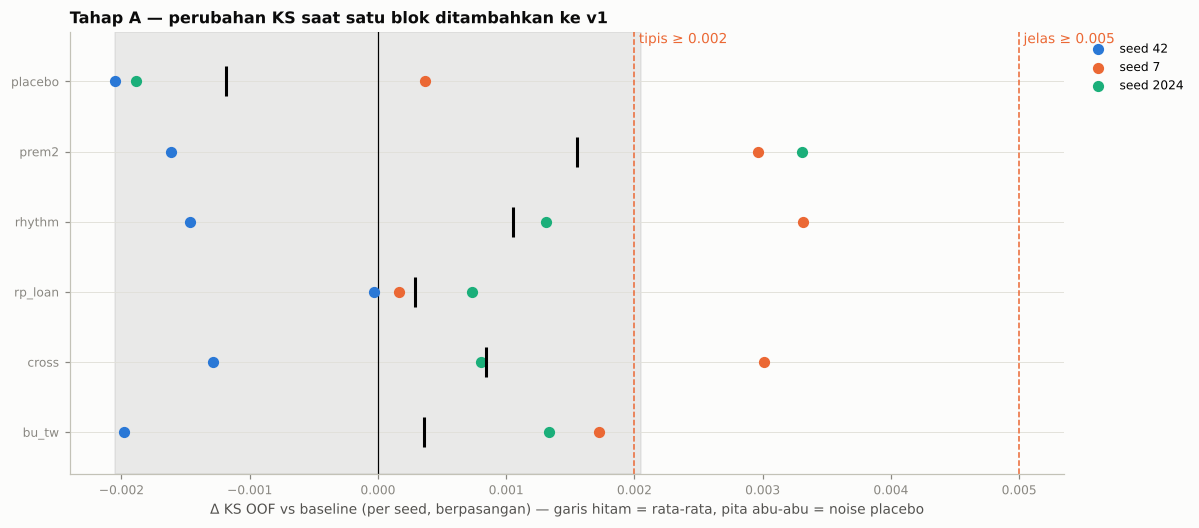

In [8]:
def plot_deltas(names, title, labels=None):
    labels = labels or names
    fig, ax = plt.subplots(figsize=(11, 0.55 * len(names) + 1.6))
    for i, n in enumerate(names):
        ps = CMP[n]["per_seed"]
        for j, (s, v) in enumerate(zip(ps["seed"], ps["delta"])):
            ax.scatter(v, i, color=E.SERIES[j], s=40, zorder=3, label=f"seed {s}" if i == len(names) - 1 or (n == names[-1]) else None)
        ax.scatter(ps["delta"].mean(), i, marker="|", s=400, color="black", zorder=4)
    ax.axvspan(-PLACEBO_NOISE, PLACEBO_NOISE, color="grey", alpha=0.15)
    ax.axvline(0, color="black", lw=0.8)
    for x, lab in [(0.002, "tipis"), (0.005, "jelas")]:
        ax.axvline(x, color=E.SERIES[1], lw=1, ls="--")
        ax.text(x, -0.5, f" {lab} ≥ {x}", color=E.SERIES[1], fontsize=9, va="bottom")
    ax.set_yticks(range(len(names)), labels)
    ax.set_ylim(len(names) - 0.4, -0.7)
    ax.set_xlabel("Δ KS OOF vs baseline (per seed, berpasangan) — garis hitam = rata-rata, pita abu-abu = noise placebo")
    ax.set_title(title, loc="left")
    h, l = ax.get_legend_handles_labels()
    ax.legend(h, l, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
    plt.tight_layout(); plt.show()

plot_deltas(["placebo"] + V.BLOCKS, "Tahap A — perubahan KS saat satu blok ditambahkan ke v1")

**Cara membaca:** setiap titik adalah Δ KS satu seed, dan garis hitam vertikal adalah rata-ratanya. Blok yang berguna punya rata-rata di kanan pita abu-abu (noise placebo). Blok yang titiknya tersebar di sekitar nol tidak membawa informasi baru, meskipun KS univariat fiturnya tinggi. Biasanya itu karena informasinya sudah terwakili fitur v1.

Tahap A hanya untuk **mengurutkan** blok. Dengan 3 seed, satu blok jarang lolos sendirian karena peningkatannya biasanya kecil (+0,001 s.d. +0,003). Keputusan diambil di tahap B dengan 5 seed.

Perubahan per segmen (OOF gabungan 3 seed) menunjukkan **siapa** yang terbantu. Segmen B kecil (±2.700 baris), jadi Δ ±0,01 di sana masih noise.

In [9]:
seg_rows = [dict(blok=b, segment=r["segment"], delta=r["delta"])
            for b in V.BLOCKS for r in CMP[b]["per_segment"].iter_rows(named=True)]
(pl.DataFrame(seg_rows).pivot(on="segment", index="blok", values="delta")
   .with_columns(pl.col(pl.Float64).round(4)))

blok,SEMUA,A_no_history,B_apps_no_installments,C_has_installments
str,f64,f64,f64,f64
"""prem2""",0.0024,0.0017,0.0024,0.0028
"""rhythm""",0.0007,0.0005,0.0029,0.0002
"""rp_loan""",0.0003,-0.0003,0.0055,-0.0001
"""cross""",0.001,0.0026,0.0142,0.0011
"""bu_tw""",0.0001,0.0011,0.0009,0.0021


## 4. Tahap B — kombinasi kumulatif (5 seed)

Blok ber-Δ positif ditambahkan satu per satu sesuai peringkat tahap A. Kurvanya menunjukkan apakah blok tambahan masih membantu atau mulai mengencerkan model.

In [10]:
COMBOS = []
ks_range = [2, 3] if QUICK else range(1, len(RANKED) + 1)
for k in ks_range:
    if k > len(RANKED):
        continue
    name = "top" + str(k) + ": " + " + ".join(RANKED[:k])
    t = time.time()
    tr, te, feats = with_block(RANKED[:k])
    RUNS[name] = M.train_lgb_cv(tr, te, feats, CATS, seeds=SEEDS_B, verbose=False)
    CMP[name] = M.compare_runs(base, RUNS[name], y, SEG)
    COMBOS.append(name)
    print(f"{name:45s} Δ per seed {[round(d, 4) for d in CMP[name]['per_seed']['delta']]} "
          f"| rata-rata {CMP[name]['delta_seed_mean']:+.4f} | {time.time() - t:.0f} detik")
    del tr, te; gc.collect()

stage_b = pl.DataFrame([summary_row(c, CMP[c], len(RUNS[c]["features"]) - len(FEAT_V1)) for c in COMBOS])
stage_b = stage_b.with_columns(keputusan=pl.Series([M.verdict(CMP[c], noise=PLACEBO_NOISE) for c in COMBOS]))
stage_b.with_columns(pl.col(pl.Float64).round(4))

top1: prem2                                   Δ per seed [-0.0016, 0.003, 0.0033, 0.0019, 0.0015] | rata-rata +0.0016 | 305 detik


top2: prem2 + rhythm                          Δ per seed [-0.0005, 0.003, 0.0028, -0.0014, 0.0042] | rata-rata +0.0016 | 330 detik


top3: prem2 + rhythm + cross                  Δ per seed [0.0002, 0.0049, 0.0037, 0.0024, 0.0022] | rata-rata +0.0027 | 329 detik


top4: prem2 + rhythm + cross + bu_tw          Δ per seed [-0.001, 0.0034, 0.0002, -0.0001, 0.001] | rata-rata +0.0007 | 345 detik


top5: prem2 + rhythm + cross + bu_tw + rp_loan Δ per seed [-0.0017, 0.0005, 0.0002, 0.0001, 0.0018] | rata-rata +0.0002 | 375 detik


eksperimen,n_fitur_baru,delta_oof,d_s42,d_s7,d_s2024,d_s11,d_s99,delta_rata2,seed_naik,keputusan
str,i64,f64,f64,f64,f64,f64,f64,f64,str,str
"""top1: prem2""",8,0.0019,-0.0016,0.003,0.0033,0.0019,0.0015,0.0016,"""4/5""","""tidak"""
"""top2: prem2 + rhythm""",19,0.002,-0.0005,0.003,0.0028,-0.0014,0.0042,0.0016,"""3/5""","""tidak"""
"""top3: prem2 + rhythm + cross""",26,0.002,0.0002,0.0049,0.0037,0.0024,0.0022,0.0027,"""5/5""","""tipis"""
"""top4: prem2 + rhythm + cross + bu_tw""",36,0.0007,-0.001,0.0034,0.0002,-0.0001,0.001,0.0007,"""3/5""","""tidak"""
"""top5: prem2 + rhythm + cross + bu_tw + rp_loan""",49,0.0004,-0.0017,0.0005,0.0002,0.0001,0.0018,0.0002,"""4/5""","""tidak"""


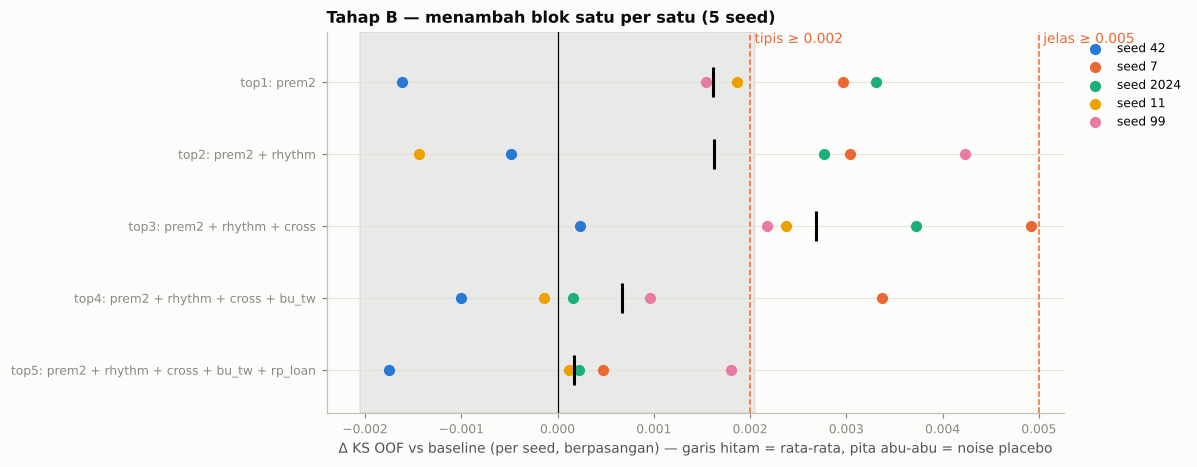

In [11]:
if COMBOS:
    plot_deltas(COMBOS, "Tahap B — menambah blok satu per satu (5 seed)")

**Cara membaca:** yang dicari adalah titik ketika garis hitam (rata-rata) paling ke kanan **dan** semua titik seed di kanan nol. Kalau rata-rata turun setelah blok tertentu masuk, blok itu tumpang tindih dengan yang lain atau hanya menambah noise. Kombinasi terbaik dipilih dari kurva ini. Memilih yang terbaik dari beberapa kombinasi memberi sedikit optimisme (paling banyak sebesar noise placebo), jadi kombinasi itu tetap harus lolos aturan keputusan.

In [12]:
if COMBOS:
    BEST = max(COMBOS, key=lambda c: CMP[c]["delta_seed_mean"])
    V2_VERDICT = M.verdict(CMP[BEST], noise=PLACEBO_NOISE)
    ACCEPTED = RANKED[: int(BEST.split(":")[0][3:])]
    print(f"Kombinasi terbaik: {BEST}")
    print(f"KS OOF 5 seed: {RUNS[BEST]['ks_oof']:.4f} vs baseline {base['ks_oof']:.4f} "
          f"(Δ {CMP[BEST]['delta_oof']:+.4f}) | Δ rata-rata seed {CMP[BEST]['delta_seed_mean']:+.4f} "
          f"| seed naik {CMP[BEST]['n_seed_positive']}/5 | keputusan: {V2_VERDICT}")
    display(CMP[BEST]["per_segment"].with_columns(pl.col(pl.Float64).round(4)))
else:
    BEST, V2_VERDICT, ACCEPTED = None, "tidak", []
    print("Tidak ada blok ber-Δ positif di tahap A → tetap v1.")

Kombinasi terbaik: top3: prem2 + rhythm + cross
KS OOF 5 seed: 0.5099 vs baseline 0.5079 (Δ +0.0020) | Δ rata-rata seed +0.0027 | seed naik 5/5 | keputusan: tipis


segment,n,ks_base,ks_baru,delta
str,i64,f64,f64,f64
"""SEMUA""",70000,0.5079,0.5099,0.002
"""A_no_history""",21000,0.4706,0.4723,0.0017
"""B_apps_no_installments""",2688,0.4665,0.4705,0.0041
"""C_has_installments""",46312,0.5269,0.5274,0.0005


### Fitur baru mana yang dipakai model terbaik?

In [13]:
if BEST:
    FEAT_V2 = RUNS[BEST]["features"]
    new_feats = [c for c in FEAT_V2 if c not in FEAT_V1]
    imp = RUNS[BEST]["importance"].with_columns(peringkat=pl.int_range(1, pl.len() + 1),
                                                 baru=pl.col("feature").is_in(new_feats))
    print(f"Porsi gain fitur baru: {imp.filter(pl.col('baru'))['gain_pct'].sum():.1f}% dari {len(new_feats)} fitur baru")
    display(imp.filter(pl.col("baru")).head(15).with_columns(pl.col("gain_pct").round(2)))

Porsi gain fitur baru: 15.7% dari 26 fitur baru


feature,gain_pct,peringkat,baru
str,f64,i64,bool
"""ec_prem_shrunk""",5.74,3,true
"""ec_recency_vs_rhythm""",1.7,9,true
"""xs_inst_to_ac_inflow""",1.14,13,true
"""ec_orders_14d_vs_base""",0.69,23,true
"""ec_prem_pos_share""",0.66,24,true
"""ec_prem_q75""",0.59,28,true
"""ec_gap_mean_base""",0.57,29,true
"""ec_prem_trend_90d""",0.57,30,true
"""ec_prem_cod""",0.42,35,true


## 5. Simpan v2 & submission

Dijalankan hanya bila kombinasi terbaik lolos. Tabel v2 = v1 + blok yang lolos, disimpan seperti v1 sehingga notebook berikutnya (tuning, ensemble) cukup membaca `train_v2.parquet`. Prediksi test diambil dari model 5 seed (25 model).

In [14]:
if V2_VERDICT in ("jelas", "tipis"):
    tr_v2, te_v2, FEAT_V2 = with_block(ACCEPTED)
    tr_v2.write_parquet(M.FEAT_DIR / "train_v2.parquet")
    te_v2.write_parquet(M.FEAT_DIR / "test_v2.parquet")
    meta_v2 = {**meta_v1, "version": "v2", "created": time.strftime("%Y-%m-%d %H:%M:%S"),
               "features": FEAT_V2, "blocks_added": ACCEPTED, "premium_prior": prior,
               "groups": {g: [c for c in FEAT_V2 if F.feature_group(c) == g] for g in F.FEATURE_GROUPS_V2}}
    (M.FEAT_DIR / "features_v2.json").write_text(json.dumps(meta_v2, indent=2))
    M.save_run("lgbm_v1_5seed", train, test, base, extra=dict(feature_version="v1"))
    M.save_run("lgbm_v2", tr_v2, te_v2, RUNS[BEST], extra=dict(
        feature_version="v2", blocks_added=ACCEPTED, delta_vs_v1=CMP[BEST]["delta_oof"], verdict=V2_VERDICT))
    ss = pl.read_parquet(E.PQ_DIR / "sample_submission.parquet")
    M.make_submission(te_v2["application_id"], RUNS[BEST]["test_pred"], ss, M.SUB_DIR / "sub_v2_lgbm.csv")
    r1 = np.argsort(np.argsort(RUNS[BEST]["test_pred"])); r0 = np.argsort(np.argsort(base["test_pred"]))
    print(f"Korelasi peringkat prediksi test v2 vs v1: {np.corrcoef(r1, r0)[0, 1]:.4f}")
else:
    print("Kombinasi terbaik tidak lolos → tetap memakai v1. Tidak ada file v2 yang ditulis.")

✅ kolom tepat [application_id, default_probability]
✅ jumlah baris = sample_submission
✅ application_id unik
✅ semua ID test ada & tidak ada ID asing
✅ probabilitas finite
✅ probabilitas dalam [0, 1]
✅ prediksi tidak konstan
Tersimpan: /home/claude/credit_risk/submissions/sub_v2_lgbm.csv  (30,000 baris)
Korelasi peringkat prediksi test v2 vs v1: 0.9957
